# 05 — Comparación final en el conjunto de prueba

Cada modelo se arma con los mejores hiperparámetros del cuaderno 04, se **reajusta con todo el conjunto de desarrollo** y
se evalúa **una sola vez** en la prueba. El mejor modelo se elige por validación cruzada, no por prueba.

In [1]:
import sys
sys.path.append("../src")  # por si el paquete no está instalado con pip install -e .

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto_ml.data import SEMILLA, cargar_dataset, particionar
from proyecto_ml.metrics import resumen, rmse
from proyecto_ml.models import ARBOL, BOSQUE, KNN, LINEA_BASE, LINEAL, NOMBRES, construir_modelo

RESULTADOS = Path("..") / "resultados"
RESULTADOS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)

import json
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold, cross_validate
from proyecto_ml.metrics import diferencia_bootstrap
from proyecto_ml.simulation import piso_de_error

In [2]:
datos = cargar_dataset()
X_dev, X_test, y_dev, y_test = particionar(datos)   # 80 % desarrollo, 20 % prueba (reservada)
print("desarrollo:", X_dev.shape, "| prueba:", X_test.shape)

desarrollo: (6972, 7) | prueba: (1744, 7)


## Modelos finales

In [3]:
with open(RESULTADOS / "mejores_hiperparametros.json") as f:
    mejores = json.load(f)

# De las dos búsquedas del Random Forest se usa la de menor RMSE en validación cruzada.
clave_bosque = min(["Random Forest (grid)", "Random Forest (random)"], key=lambda k: mejores[k]["rmse_cv"])
configuracion = {
    LINEA_BASE: {},
    LINEAL: {},
    ARBOL: mejores[ARBOL]["params"],
    BOSQUE: mejores[clave_bosque]["params"],
    KNN: mejores[KNN]["params"],
}
print("Random Forest elegido:", clave_bosque)
modelos = {nombre: construir_modelo(nombre, **params).fit(X_dev, y_dev) for nombre, params in configuracion.items()}
pd.Series({n: p for n, p in configuracion.items()}, name="hiperparámetros").to_frame()

Random Forest elegido: Random Forest (grid)


,hiperparámetros
Línea base (media),{}
Regresión lineal,{}
Árbol de decisión,"{'max_depth': 8, 'min_samples_leaf': 10}"
Random Forest,"{'n_estimators': 50, 'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf'..."
kNN,"{'n_neighbors': 20, 'p': 2, 'weights': 'uniform'}"


## Tabla comparativa

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in modelos.items():
    r_cv = cross_validate(construir_modelo(nombre, **configuracion[nombre]), X_dev, y_dev, cv=cv,
                          scoring="neg_root_mean_squared_error")
    entrenamiento = resumen(y_dev, modelo.predict(X_dev))
    prueba = resumen(y_test, modelo.predict(X_test))
    filas.append({
        "modelo": nombre,
        "RMSE entrenamiento": entrenamiento["RMSE"],
        "RMSE validación cruzada": -r_cv["test_score"].mean(),
        "RMSE prueba": prueba["RMSE"],
        "MAE prueba": prueba["MAE"],
        "R2 prueba": prueba["R2"],
        "brecha (prueba - entrenamiento)": prueba["RMSE"] - entrenamiento["RMSE"],
    })
tabla_final = pd.DataFrame(filas)
mejor_cv = tabla_final.loc[tabla_final["RMSE validación cruzada"].idxmin(), "modelo"]
print("Mejor modelo por validación cruzada:", mejor_cv)
tabla_final

Mejor modelo por validación cruzada: Random Forest


,modelo,RMSE entrenamiento,RMSE validación cruzada,RMSE prueba,MAE prueba,R2 prueba,brecha (prueba - entrenamiento)
0,Línea base (media),3.053,3.052,3.099,2.451,-0.001,0.047
1,Regresión lineal,1.432,1.440,1.522,1.123,0.758,0.090
2,Árbol de decisión,1.202,1.258,1.344,0.990,0.812,0.142
3,Random Forest,1.186,1.252,1.333,0.982,0.815,0.147
4,kNN,1.329,1.394,1.469,1.078,0.775,0.139


## ¿Cuánto error era imposible de evitar?

El azar del simulador (meses trabajados y factor de ingreso de cada persona) no lo puede predecir ningún modelo.
Se simula 200 veces el objetivo de cada persona: el promedio es el **predictor ideal** (conoce estrato, año, valor y programa,
pero no el azar) y la varianza es el **error irreducible**.

In [5]:
promedio, varianza = piso_de_error(datos.drop(columns="anios_pago"), repeticiones=200)
idx_prueba = X_test.index

piso = float(np.sqrt(varianza[idx_prueba].mean()))
ideal_prueba = rmse(y_test, promedio[idx_prueba])
print(f"Piso de error esperado (raíz de la varianza irreducible): {piso:.3f} años")
print(f"RMSE del predictor ideal sobre esta prueba:                {ideal_prueba:.3f} años")

Piso de error esperado (raíz de la varianza irreducible): 1.229 años
RMSE del predictor ideal sobre esta prueba:                1.318 años


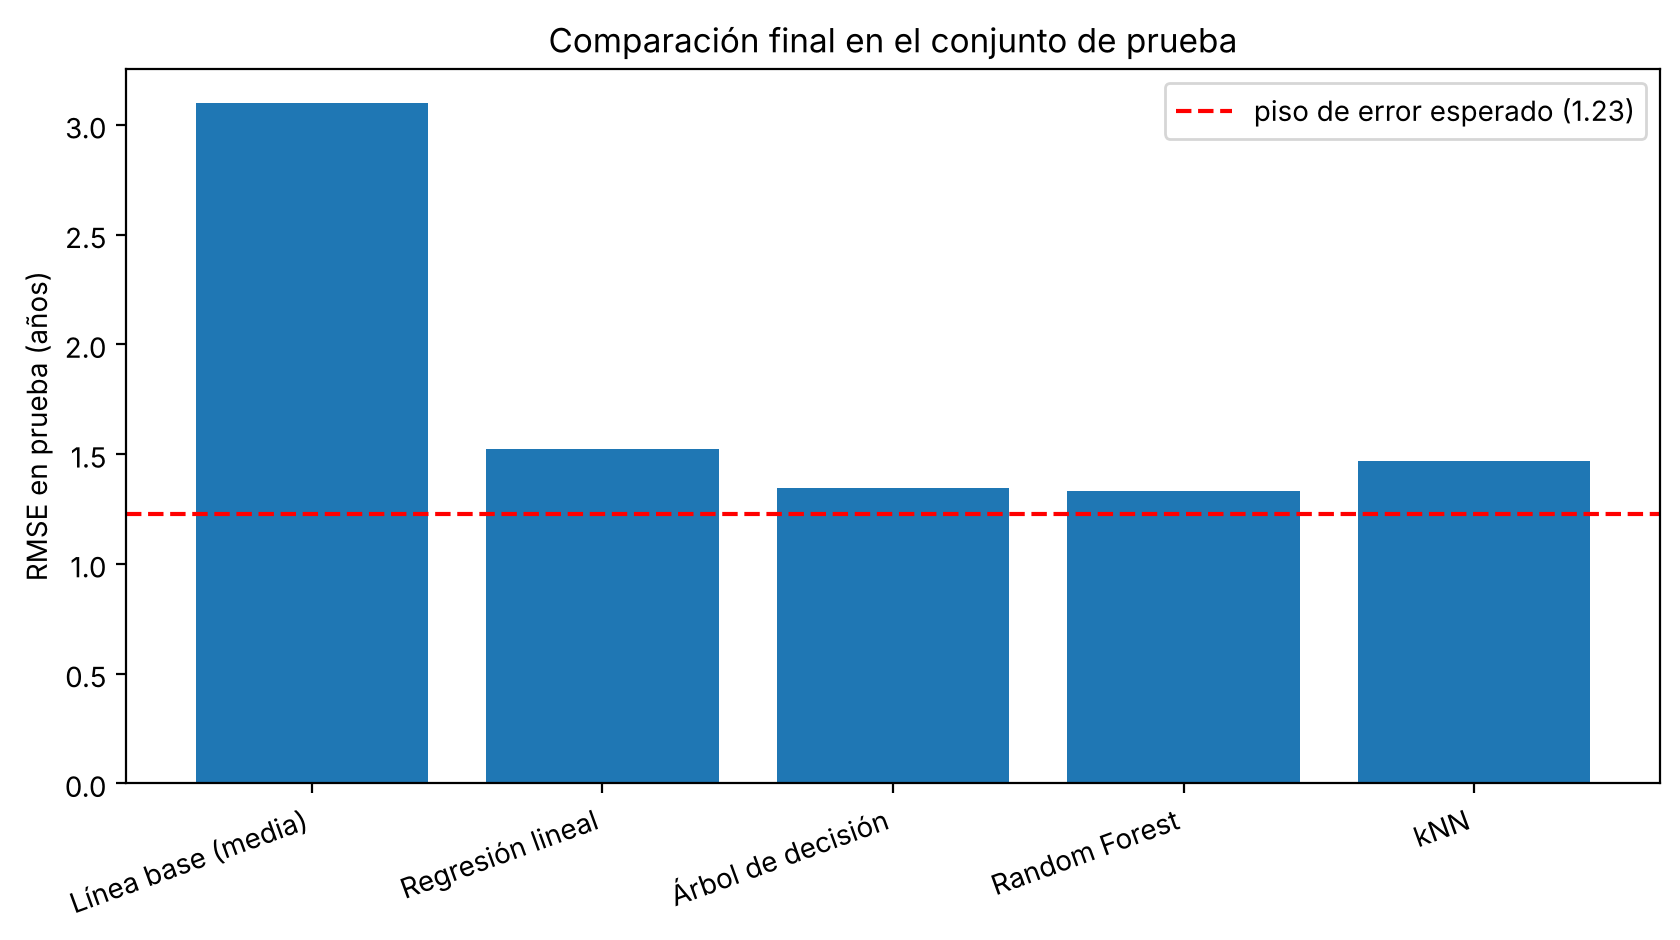

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.bar(range(len(tabla_final)), tabla_final["RMSE prueba"], color="tab:blue")
ax.set_xticks(range(len(tabla_final)))
ax.axhline(piso, color="red", linestyle="--", label=f"piso de error esperado ({piso:.2f})")
ax.set_ylabel("RMSE en prueba (años)")
ax.set_title("Comparación final en el conjunto de prueba")
ax.set_xticklabels(tabla_final["modelo"], rotation=20, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTADOS / "05_comparacion_final.png", dpi=150)
plt.show()

## ¿Las diferencias son reales o ruido?

Con una prueba de 1.744 personas, una diferencia pequeña de RMSE puede ser azar. Se compara cada modelo con el mejor (por validación
cruzada) usando **bootstrap pareado**: si el intervalo de confianza del 95 % de la diferencia contiene el 0, no se distinguen.

In [7]:
pred_mejor = modelos[mejor_cv].predict(X_test)
filas = []
for nombre, modelo in modelos.items():
    if nombre == mejor_cv:
        continue
    dif, inf, sup = diferencia_bootstrap(y_test, modelo.predict(X_test), pred_mejor)
    filas.append({
        "modelo": nombre,
        f"RMSE(modelo) - RMSE({mejor_cv})": dif,
        "IC 95 % inferior": inf,
        "IC 95 % superior": sup,
        "se distingue del mejor": "sí" if (inf > 0 or sup < 0) else "no",
    })
pd.DataFrame(filas)

,modelo,RMSE(modelo) - RMSE(Random Forest),IC 95 % inferior,IC 95 % superior,se distingue del mejor
0,Línea base (media),1.768,1.651,1.887,sí
1,Regresión lineal,0.189,0.133,0.249,sí
2,Árbol de decisión,0.011,0.001,0.021,sí
3,kNN,0.136,0.091,0.182,sí


## Predicciones contra valores reales

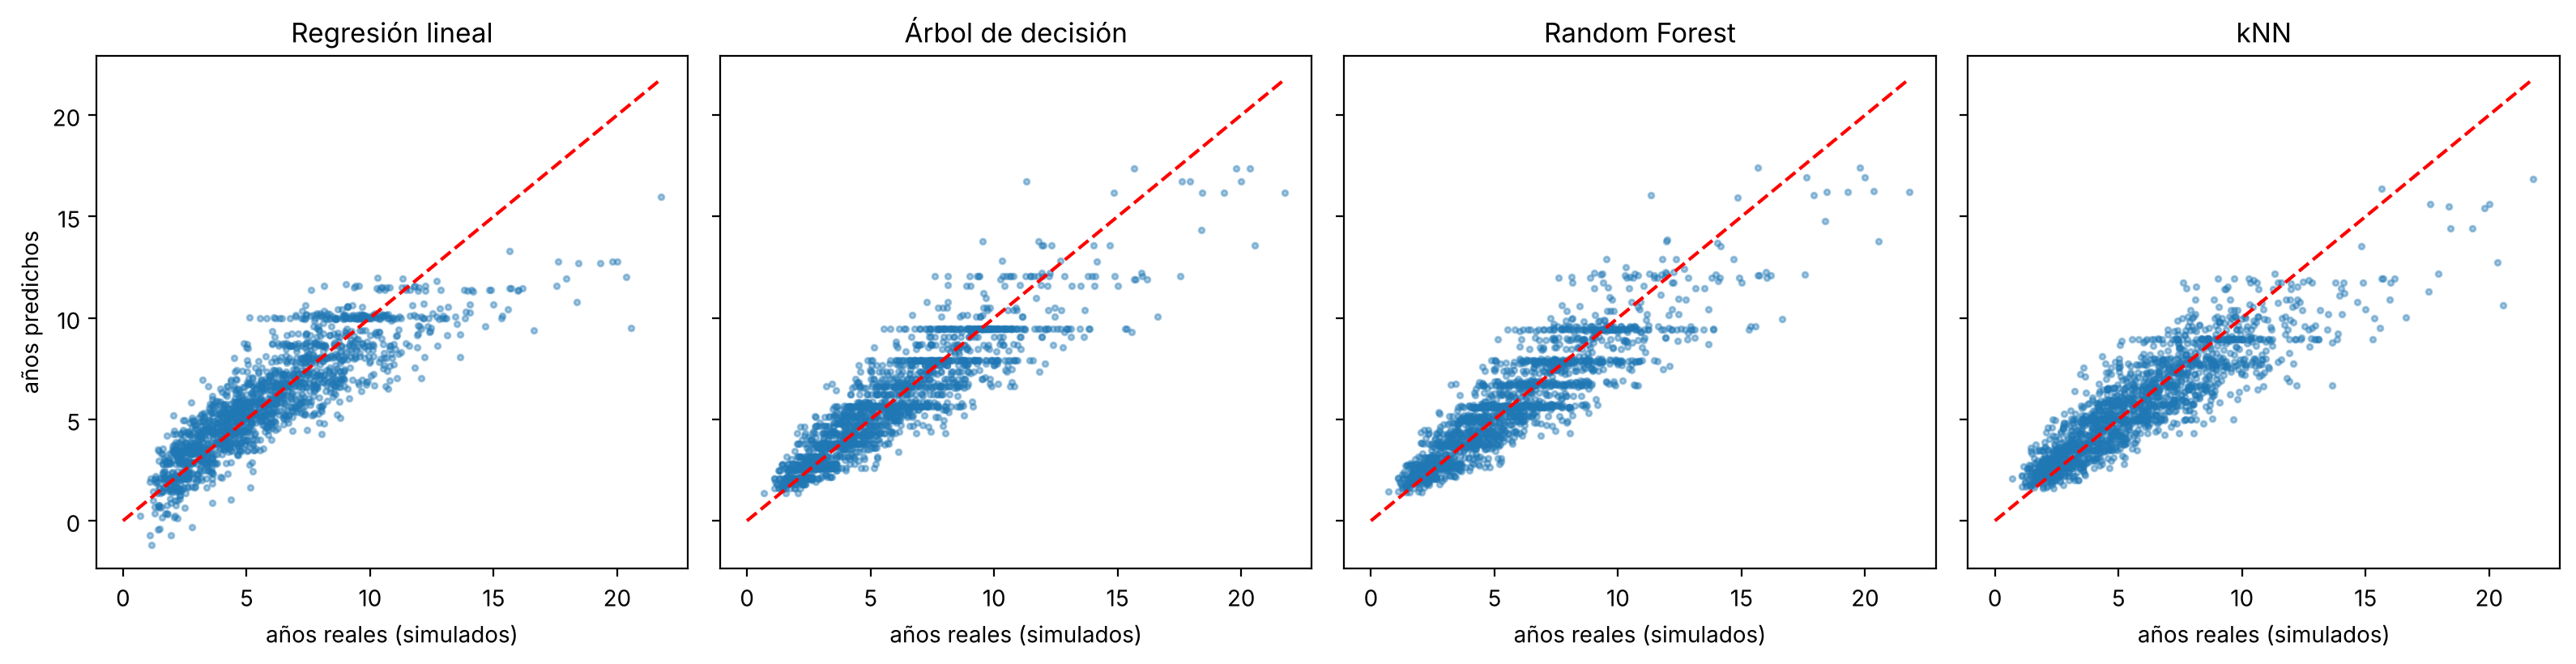

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
for ax, nombre in zip(axes, [LINEAL, ARBOL, BOSQUE, KNN]):
    ax.scatter(y_test, modelos[nombre].predict(X_test), s=6, alpha=0.4)
    limite = [0, max(y_test.max(), 1)]
    ax.plot(limite, limite, "r--")
    ax.set_title(nombre)
    ax.set_xlabel("años reales (simulados)")
axes[0].set_ylabel("años predichos")
plt.tight_layout()
plt.savefig(RESULTADOS / "05_predicho_vs_real.png", dpi=150)
plt.show()

## ¿Qué variables usa el modelo?

**Importancia por permutación:** se baraja una variable a la vez en la prueba y se mide cuánto empeora el RMSE. Si baraja una
variable y el error casi no cambia, el modelo no la usa. En el simulador solo importan estrato, año de inicio, valor comprometido y programa;
género, tipo de institución y departamento no tienen ningún efecto.

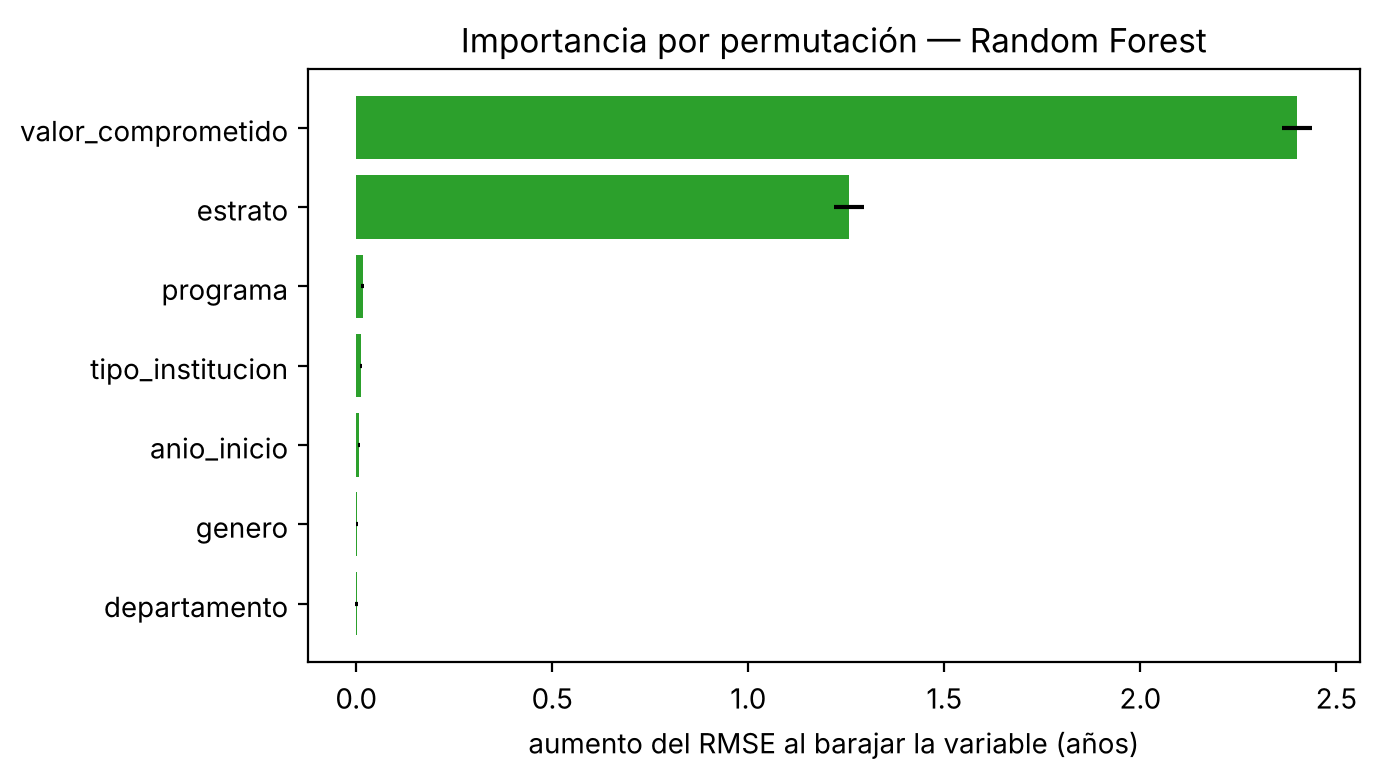

,variable,aumento del RMSE,desv
0,valor_comprometido,2.400,0.039
1,estrato,1.257,0.039
2,programa,0.016,0.004
3,tipo_institucion,0.013,0.003
4,anio_inicio,0.007,0.003
5,genero,0.002,0.004
6,departamento,0.001,0.003


In [9]:
imp = permutation_importance(modelos[mejor_cv], X_test, y_test, scoring="neg_root_mean_squared_error",
                             n_repeats=10, random_state=SEMILLA)
importancia = pd.DataFrame({"variable": X_test.columns, "aumento del RMSE": imp.importances_mean,
                            "desv": imp.importances_std}).sort_values("aumento del RMSE")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importancia["variable"], importancia["aumento del RMSE"], xerr=importancia["desv"], color="tab:green")
ax.set_xlabel("aumento del RMSE al barajar la variable (años)")
ax.set_title(f"Importancia por permutación — {mejor_cv}")
plt.tight_layout()
plt.savefig(RESULTADOS / "05_importancia_variables.png", dpi=150)
plt.show()
importancia.sort_values("aumento del RMSE", ascending=False).reset_index(drop=True)

### Lectura de resultados
- **Ranking en prueba (RMSE, años):** Random Forest 1,333; árbol 1,344; kNN 1,469; regresión lineal 1,522; línea base 3,099. El mejor por validación cruzada (Random Forest) también fue el mejor en prueba.
- **Piso de error:** el error esperado imposible de evitar es 1,229 años, y el predictor ideal sobre esta prueba obtiene 1,318. El Random Forest queda a solo 0,015 años del predictor ideal: casi no hay margen de mejora, el resto es azar del simulador.
- **Bootstrap pareado:** todos los modelos se distinguen del Random Forest, pero la diferencia con el árbol es de 0,011 años (IC 95 %: 0,001 a 0,021), estadísticamente distinta de 0 y prácticamente irrelevante (unos 4 días). Árbol y Random Forest empatan en la práctica; kNN (+0,14) y la regresión lineal (+0,19) sí son peores.
- **Por qué pierde la regresión lineal:** en el simulador los años son aproximadamente proporcionales a valor comprometido / (porcentaje del estrato), una relación no lineal que un modelo lineal no captura.
- **Sobreajuste:** la brecha entre prueba y entrenamiento es ≈ 0,14 a 0,15 para árbol, bosque y kNN y 0,09 para la lineal. Con hiperparámetros ajustados, ningún modelo sobreajusta mucho.
- **Variables:** valor comprometido (+2,40 años de RMSE al barajarlo) y estrato (+1,26) concentran casi toda la importancia. Programa y tipo de institución (+0,02, traen la misma información), año de inicio (+0,007), género y departamento (≈ 0) casi no se usan, como se programó en el simulador.
- **Límite:** todo esto describe el simulador, no el comportamiento real de ICETEX.

### Mi análisis
*(Escríbelo con tus palabras. Preguntas para guiarte: ¿qué modelo ganó y por cuánto frente al piso de error? ¿Las diferencias entre modelos son estadísticamente reales? ¿Qué modelo sobreajusta más, según la brecha entre entrenamiento y prueba? ¿Qué variables usa el modelo y coincide con lo que se programó en el simulador? ¿Qué limitaciones tiene concluir algo sobre ICETEX a partir de un objetivo simulado?)*